# Model 3: Fine-tuning Clinical BERT

**Goal:** predict the medical specialty of a clinical note (12 classes) with a **pre-trained Transformer** that already "knows" clinical language, then **fine-tune** it on our data.

**The idea in one sentence:** take Bio_ClinicalBERT, a BERT model pre-trained on millions of clinical notes, put a small classification layer on top, and train the whole thing for a few epochs on our 2,669 labelled notes.

**The final system has three layers**, applied in this order to each note:
1. **Keyword rule:** if the note's first keyword names a specialty (true for 83% of training notes and 80% of test notes), answer that specialty.
2. **Clinical BERT** reads the text of the remaining notes (those with no keywords) and scores the 12 specialties.
3. **Duplicate-note rule:** if that note also appears in the training data, the labels it already has there are ruled out.

Layers 1 and 3 exploit how the dataset was built. Layer 2 is the actual language model. The evaluation reports each layer separately so the paper can show how much each contributes.

**How the three models differ**
Model 2 is the intermediate baseline: it extends Model 1's TF-IDF representation with word bigrams and uses balanced Logistic Regression, before Model 3 moves to contextual representations from Clinical BERT.
| | Model 1 (TF-IDF + SVM) | Model 2 (TF-IDF + Logistic Regression) | Model 3 (Clinical BERT) |
|---|---|---|---|
| Data preparation | removes the first label-leaking keyword; keeps conflicting duplicate labels | removes the first label-leaking keyword; keeps the modal label for duplicate texts; augments minority classes (<100) with random word swaps | removes the first label-leaking keyword; uses the same stratified split; applies keyword and duplicate-note rules during evaluation |
| Representation | TF-IDF word scores | TF-IDF word and bigram scores (ngram_range=(1, 2)) | contextual token representations from Bio_ClinicalBERT |
| Classifier | balanced LinearSVC (C=0.3) | balanced LogisticRegression (max_iter=1000) | BERT classification head fine-tuned for 12 classes |
| Prior knowledge | none | none | pre-trained on ~2 million clinical notes (MIMIC-III) |
| Input limit | whole note | whole note | first **512 tokens** |
| Cost | seconds on CPU | seconds on CPU | minutes on a GPU |.

Steps:
0. Setup 
1. Settings (hyperparameters)
2. Load the data and remove the leaked keyword
3. Build the input text
4. Split into train / test
5. Tokenize (subwords)
6. The model: BERT + classification head
7. Training loop
8. Evaluate layer by layer: BERT alone → + duplicate rule → + keyword rule
9. Look at mistakes
10. Final model → `results.txt`

## 0. Setup

The first run downloads Bio_ClinicalBERT from Hugging Face. Later runs use the cached copy.

**Reproducibility:** we fix all random seeds, so the data split, the classification-layer initialisation and the batch order are the same on every run. 

In [4]:
import random, time
import numpy as np
import pandas as pd
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
import transformers, sklearn
print("PyTorch", torch.__version__, "| transformers", transformers.__version__, "| scikit-learn", sklearn.__version__)
print("device:", device,
      "|", torch.cuda.get_device_name(0) if device == "cuda" else "no GPU found: training will be very slow")

PyTorch 2.14.1+cpu | transformers 5.20.1 | scikit-learn 1.7.2
device: cpu | no GPU found: training will be very slow


## 1. Settings (hyperparameters)
All the knobs are in one place so they are easy to report in the paper (*Experimental Setup → Hyperparameters*).

| Setting | Value | What it means |
|---|---|---|
| `MODEL_NAME` | Bio_ClinicalBERT | the pre-trained model we start from (Alsentzer et al., 2019) |
| `MAX_LEN` | 512 | max number of tokens per note; BERT cannot read more. Longer notes are cut (truncated) |
| `BATCH_SIZE` | 8 | notes processed together in one forward pass (limited by GPU memory: 16 GB) |
| `GRAD_ACCUM` | 2 | accumulate gradients over 2 batches before updating, so the **effective batch is 16** |
| `EPOCHS` | 4 | passes over the training data. The BERT paper recommends 2–4 for fine-tuning |
| `LR` | 2e-5 | learning rate: how big each weight update is. Small, because we only want to *adjust* pre-trained weights, not overwrite them |
| `WARMUP` | 0.1 | the learning rate rises from 0 during the first 10% of steps, then decreases linearly to 0, which stabilises the start |
| `WEIGHT_DECAY` | 0.01 | small penalty on large weights (regularisation, like C in the SVM) |
| `SEEDS` | 42, 7, 123 | random seeds for the repeated runs in section 8.6 (mean ± std). The main run and `results.txt` use seed 42 |

In [6]:
MODEL_NAME   = "emilyalsentzer/Bio_ClinicalBERT"
MAX_LEN      = 512
BATCH_SIZE   = 8
GRAD_ACCUM   = 2
EPOCHS       = 4
LR           = 2e-5
WARMUP       = 0.1
WEIGHT_DECAY = 0.01
SEEDS        = [42, 7, 123]   # section 8.6; set to [42] to skip the extra runs

## 2. Load the data; separate the keyword from the text
In every training note that has keywords, the **first keyword is the specialty itself** (2,219 of 2,219). We use it in two different ways:
* **As a rule (layer 1):** we keep the original keywords in `keywords_raw` and read the specialty from the first one.
* **For BERT (layer 2):** we **remove** the first keyword from the text, so BERT has to learn from the clinical content. That's also the situation BERT faces at prediction time: it only decides notes *without* keywords.

**No other pre-processing.** No lowercasing, stemming or stop-word removal. BERT was pre-trained on raw text with its own tokenizer, so "cleaning" the text would make it look *less* like what the model knows (lecture T2: *pre-processing is probably not a good idea with these models*).

In [7]:
train = pd.read_csv("train_clean.csv", sep=";", dtype=str, keep_default_na=False)

def drop_first_keyword(keywords):
    return ",".join(keywords.split(",")[1:])

def keyword_specialty(keywords):
    # 'cardiovascular / pulmonary, chest pain, ...' -> 'Cardiovascular-Pulmonary'; None if no keyword
    first = keywords.split(",")[0].strip().lower().replace(" / ", "-").replace("/", "-")
    return {l.lower(): l for l in train["medical_specialty"].unique()}.get(first)

train["keywords_raw"] = train["keywords"]
train["keywords"] = train["keywords"].apply(drop_first_keyword)

rule = train["keywords_raw"].apply(keyword_specialty)
has_rule = rule.notna()
print(f"notes whose first keyword names a specialty: {has_rule.sum()} of {len(train)}; "
      f"rule agrees with the label in {(rule[has_rule] == train.loc[has_rule, 'medical_specialty']).mean():.1%} of them")

LABELS = sorted(train["medical_specialty"].unique())
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}
print(train.shape, "|", len(LABELS), "classes")

notes whose first keyword names a specialty: 2219 of 2669; rule agrees with the label in 100.0% of them
(2669, 6) | 12 classes


## 3. Build the input text
BERT reads at most 512 tokens, and the median transcription alone is ~390 words (≈ 500+ tokens). So **order matters**: whatever comes last gets cut. We put the **short, information-dense fields first**:

`sample_name [SEP] description [SEP] keywords [SEP] transcription`

`[SEP]` is BERT's own separator token, which tells the model where one field ends and the next begins. The transcription comes last, so if anything is truncated it's the end of the transcription, which is usually the least informative part (closing remarks, sutures, follow-up).

In [8]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
SEP = f" {tokenizer.sep_token} "

def build_text(df):
    return df["sample_name"] + SEP + df["description"] + SEP + df["keywords"] + SEP + df["transcription"]

texts = build_text(train)
print(texts[0][:400])

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

c:\Users\migue\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\migue\.cache\huggingface\hub\models--emilyalsentzer--Bio_ClinicalBERT. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

 Chest Pain - Cardiac Consult  [SEP]  Chest pain, possible syncopal spells.  She has been having multiple cardiovascular complaints including chest pains, which feel like cramps and sometimes like a dull ache, which will last all day long. [SEP]  chest pain, syncopal, echocardiogram, ekg, cardiac etiology, syncopal spells, rhythm, flexeril, cardiac, chest,  [SEP] REASON FOR REFERRAL:  Chest pain, 


## 4. Split into train / test
**Same split as Model 1** (`test_size=0.2, stratify, random_state=42`), so the scores are directly comparable. It's a random split, so, as in the official test set, some notes appear in both parts with **different labels** (see section 8).

In [9]:
from sklearn.model_selection import train_test_split

idx_train, idx_test = train_test_split(
    train.index, test_size=0.2, stratify=train["medical_specialty"], random_state=SEED)
tr, te = train.loc[idx_train], train.loc[idx_test]
print(len(tr), "training notes,", len(te), "test notes")

2135 training notes, 534 test notes


## 5. Tokenize (lecture T4: subword tokenization)
BERT uses **WordPiece**. Frequent words stay whole, and rare words are split into known pieces (`##` marks a piece that continues the previous word). There is no "unknown word" problem: any word can be built from pieces.

Each note becomes:
* `input_ids`: the token numbers, starting with **[CLS]** and ending with [SEP]
* `attention_mask`: 1 for real tokens, 0 for padding (short notes are padded to the batch length)

In [10]:
example = "Laparoscopic cholecystectomy for symptomatic cholelithiasis"
print(tokenizer.tokenize(example))

lengths = [len(tokenizer(t)["input_ids"]) for t in texts]
print(f"\nmedian tokens per note: {int(np.median(lengths))} | "
      f"notes longer than {MAX_LEN} (will be truncated): {np.mean(np.array(lengths) > MAX_LEN):.0%}")

['lap', '##aro', '##scopic', 'ch', '##ole', '##cy', '##ste', '##ct', '##omy', 'for', 's', '##ym', '##pt', '##oma', '##tic', 'ch', '##ole', '##lit', '##hia', '##sis']

median tokens per note: 746 | notes longer than 512 (will be truncated): 72%


In [11]:
from torch.utils.data import TensorDataset, DataLoader

def encode(text_series):
    enc = tokenizer(list(text_series), truncation=True, max_length=MAX_LEN,
                    padding="max_length", return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"]

def make_loader(df, shuffle, seed=SEED):
    ids, mask = encode(build_text(df))
    y = torch.tensor([label2id[l] for l in df["medical_specialty"]]) if "medical_specialty" in df else torch.zeros(len(df), dtype=torch.long)
    g = torch.Generator().manual_seed(seed)       # batch order depends on the seed
    return DataLoader(TensorDataset(ids, mask, y), batch_size=BATCH_SIZE, shuffle=shuffle, generator=g)

## 6. The model: BERT + classification head 
`AutoModelForSequenceClassification` loads the pre-trained BERT **encoder** (12 Transformer layers, 110M parameters) and adds one new **linear layer** on top:

1. The note's tokens go through 12 layers of **self-attention**. Each token's vector is updated by looking at all the other tokens, so "fracture" gets a different vector in "no fracture seen" and in "open fracture of the tibia".
2. We take the final vector of the **[CLS]** token (768 numbers), which BERT uses as a summary of the whole input.
3. The new linear layer maps those 768 numbers to **12 scores (logits)**, one per specialty. It is randomly initialised; the warning "*some weights were newly initialized*" is expected.

**Fine-tuning** = training *all* the weights (encoder + new layer) on our task, with a small learning rate.

In [12]:
from transformers import AutoModelForSequenceClassification

def new_model(seed=SEED):
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)   # initial classification layer + dropout depend on the seed
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS), id2label=id2label, label2id=label2id).to(device)

## 7. Training loop
**Loss: weighted cross-entropy.** Cross-entropy measures how far the predicted probabilities are from the true label. As in Model 1 (`class_weight="balanced"`), each class gets weight n_samples / (12 × n_class). A mistake on Dermatology (25 notes) then costs much more than one on Surgery (893 notes), so the model doesn't ignore the small classes.

For each batch:
1. **Forward pass:** compute the 12 logits for each note.
2. **Loss:** weighted cross-entropy against the true labels.
3. **Backward pass:** compute the gradients (backpropagation).
4. Every `GRAD_ACCUM` batches: **clip** the gradients (max norm 1.0, to avoid sudden huge updates), take an **AdamW** optimiser step, and advance the learning-rate **schedule** (warm-up, then linear decay).



In [13]:
from torch.nn import CrossEntropyLoss
from transformers import get_linear_schedule_with_warmup
from sklearn.utils.class_weight import compute_class_weight

def train_model(df_train, seed=SEED):
    model = new_model(seed)
    loader = make_loader(df_train, shuffle=True, seed=seed)
    weights = compute_class_weight("balanced", classes=np.array(LABELS), y=df_train["medical_specialty"])
    loss_fn = CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float, device=device))

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    total_steps = EPOCHS * int(np.ceil(len(loader) / GRAD_ACCUM))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP * total_steps), total_steps)

    model.train()
    for epoch in range(EPOCHS):
        start, running = time.time(), 0.0
        for step, (ids, mask, y) in enumerate(loader):
            ids, mask, y = ids.to(device), mask.to(device), y.to(device)
            with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(device == "cuda")):
                logits = model(input_ids=ids, attention_mask=mask).logits
            loss = loss_fn(logits.float(), y) / GRAD_ACCUM
            loss.backward()
            running += loss.item() * GRAD_ACCUM
            if (step + 1) % GRAD_ACCUM == 0 or step + 1 == len(loader):
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step(); scheduler.step(); optimizer.zero_grad()
        print(f"epoch {epoch + 1}/{EPOCHS}  mean loss {running / len(loader):.3f}  ({time.time() - start:.0f}s)")
    return model

@torch.no_grad()
def predict_scores(model, df):
    # Returns a (n_notes x 12) matrix of logits.
    model.eval()
    out = []
    for ids, mask, _ in make_loader(df, shuffle=False):
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(device == "cuda")):
            out.append(model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits.float().cpu())
    return torch.cat(out).numpy()

In [ ]:
model = train_model(tr)
scores = predict_scores(model, te)

c:\Users\migue\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\migue\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

## 8. Evaluate

### 8.1 Plain prediction: the specialty with the highest score

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1s = f1_score(y_true, y_pred, labels=LABELS, average=None, zero_division=0)
    print(f"{name}: accuracy={acc:.3f}  macro-F1={f1s.mean():.3f}  worst-class F1={f1s.min():.3f} ({LABELS[f1s.argmin()]})")

pred_plain = np.array(LABELS)[scores.argmax(axis=1)]
evaluate("Model 3, plain", te["medical_specialty"], pred_plain)

Model 3, plain: accuracy=0.549  macro-F1=0.581  worst-class F1=0.278 (Radiology)


### 8.2 The duplicate-note rule
In this dataset the **same note appears several times with different specialties** (e.g. a heart bypass note filed as both *Cardiovascular-Pulmonary* and *Surgery*), and the same (note, label) pair practically never appears twice. So, **if a test note is already in the training data with label A, its test label is almost certainly not A.**

The rule: for those notes, set the scores of the labels they already have in training to −∞, then take the best remaining one. It uses **only the training data** (never test labels). It's a property of how the dataset was built, not medical knowledge, so it is reported separately and openly in the paper.

In [12]:
def exclude_seen_labels(scores, df_test, df_train):
    seen = (df_train[df_train["transcription"].str.strip() != ""]
            .groupby("transcription")["medical_specialty"].agg(set))
    s = scores.copy()
    for i, note in enumerate(df_test["transcription"]):
        for label in seen.get(note, set()):
            s[i, label2id[label]] = -np.inf
    return np.array(LABELS)[s.argmax(axis=1)]

in_train = te["transcription"].isin(set(tr["transcription"])) & (te["transcription"].str.strip() != "")
print(f"test notes that also appear in the training part: {in_train.sum()} of {len(te)}")

pred_rule = exclude_seen_labels(scores, te, tr)
evaluate("Model 3, plain        ", te["medical_specialty"], pred_plain)
evaluate("Model 3 + note rule   ", te["medical_specialty"], pred_rule)

test notes that also appear in the training part: 240 of 534
Model 3, plain        : accuracy=0.549  macro-F1=0.581  worst-class F1=0.278 (Radiology)
Model 3 + note rule   : accuracy=0.755  macro-F1=0.746  worst-class F1=0.500 (Dermatology)


In [13]:
print(classification_report(te["medical_specialty"], pred_rule, digits=3, zero_division=0))

                          precision    recall  f1-score   support

Cardiovascular-Pulmonary      0.828     0.774     0.800        62
             Dermatology      0.429     0.600     0.500         5
        Gastroenterology      0.667     0.923     0.774        39
        General Medicine      0.680     0.810     0.739        42
               Neurology      0.757     0.757     0.757        37
            Neurosurgery      0.600     0.938     0.732        16
   Obstetrics-Gynecology      0.694     0.926     0.794        27
           Ophthalmology      0.714     1.000     0.833        15
              Orthopedic      0.619     0.867     0.722        60
   Psychiatry-Psychology      0.875     0.875     0.875         8
               Radiology      0.730     0.614     0.667        44
                 Surgery      0.966     0.631     0.764       179

                accuracy                          0.755       534
               macro avg      0.713     0.809     0.746       534
        

### 8.3 The keyword rule: the full system
Now we add layer 1: whenever a test note's first keyword names a specialty, it overrides BERT. We report two numbers:
* **Full system:** all 534 test notes. This is what the official evaluation measures.
* **BERT on notes without keywords:** only the notes the rule can't answer. This is **the part the language model really decides** at test time (78 of the 398 official test notes), so it's the fairest measure of BERT itself.

In [14]:
te_rule = te["keywords_raw"].apply(keyword_specialty)
pred_full = np.where(te_rule.notna(), te_rule, pred_rule)
no_kw = te_rule.isna().to_numpy()

print(f"test notes answered by the keyword rule: {(~no_kw).sum()} | by BERT: {no_kw.sum()}")
evaluate("Model 3, plain              ", te["medical_specialty"], pred_plain)
evaluate("+ duplicate-note rule       ", te["medical_specialty"], pred_rule)
evaluate("+ keyword rule (FULL SYSTEM)", te["medical_specialty"], pred_full)
print()
evaluate(f"BERT + duplicate rule, notes WITHOUT keywords only (n={no_kw.sum()})",
         te["medical_specialty"][no_kw], pred_rule[no_kw])

test notes answered by the keyword rule: 440 | by BERT: 94
Model 3, plain              : accuracy=0.549  macro-F1=0.581  worst-class F1=0.278 (Radiology)
+ duplicate-note rule       : accuracy=0.755  macro-F1=0.746  worst-class F1=0.500 (Dermatology)
+ keyword rule (FULL SYSTEM): accuracy=0.951  macro-F1=0.927  worst-class F1=0.800 (Dermatology)

BERT + duplicate rule, notes WITHOUT keywords only (n=94): accuracy=0.723  macro-F1=0.622  worst-class F1=0.000 (Dermatology)


In [15]:
import os
os.makedirs("figures", exist_ok=True)
print(classification_report(te["medical_specialty"], pred_full, digits=3, zero_division=0))
pd.DataFrame(classification_report(te["medical_specialty"], pred_full, output_dict=True, zero_division=0)).T.round(3) \
  .to_csv("figures/model3_per_class_full_system.csv")

                          precision    recall  f1-score   support

Cardiovascular-Pulmonary      0.982     0.871     0.923        62
             Dermatology      0.800     0.800     0.800         5
        Gastroenterology      0.925     0.949     0.937        39
        General Medicine      0.736     0.929     0.821        42
               Neurology      0.944     0.919     0.932        37
            Neurosurgery      1.000     0.938     0.968        16
   Obstetrics-Gynecology      0.962     0.926     0.943        27
           Ophthalmology      0.938     1.000     0.968        15
              Orthopedic      0.984     1.000     0.992        60
   Psychiatry-Psychology      0.875     0.875     0.875         8
               Radiology      0.977     0.977     0.977        44
                 Surgery      1.000     0.978     0.989       179

                accuracy                          0.951       534
               macro avg      0.927     0.930     0.927       534
        

### 8.3b Same rules, simpler text model: is BERT worth it?
To isolate what the Transformer adds, we swap BERT for the simple text model from Model 1 (TF-IDF + linear SVM, `C=0.3`, balanced) and keep **everything else identical**: same split, same keyword rule, same duplicate rule. The only place the two can differ is the notes **without keywords**, where the text model decides.

In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

def model1_text(df):   # Model 1's input: the 4 fields joined, first keyword already removed
    return df["description"] + " " + df["sample_name"] + " " + df["keywords"] + " " + df["transcription"]

svm = make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2),
                    LinearSVC(C=0.3, class_weight="balanced")).fit(model1_text(tr), tr["medical_specialty"])
assert list(svm.classes_) == LABELS
svm_rule = exclude_seen_labels(svm.decision_function(model1_text(te)), te, tr)
svm_full = np.where(te_rule.notna(), te_rule, svm_rule)

evaluate("SVM  + both rules (full system)", te["medical_specialty"], svm_full)
evaluate("BERT + both rules (full system)", te["medical_specialty"], pred_full)
print()
evaluate(f"SVM  + duplicate rule, notes WITHOUT keywords (n={no_kw.sum()})", te["medical_specialty"][no_kw], svm_rule[no_kw])
evaluate(f"BERT + duplicate rule, notes WITHOUT keywords (n={no_kw.sum()})", te["medical_specialty"][no_kw], pred_rule[no_kw])
print(f"\nBERT and SVM disagree on {(svm_rule[no_kw] != pred_rule[no_kw]).sum()} of the {no_kw.sum()} notes without keywords")

SVM  + both rules (full system): accuracy=0.946  macro-F1=0.931  worst-class F1=0.792 (General Medicine)
BERT + both rules (full system): accuracy=0.951  macro-F1=0.927  worst-class F1=0.800 (Dermatology)

SVM  + duplicate rule, notes WITHOUT keywords (n=94): accuracy=0.691  macro-F1=0.621  worst-class F1=0.000 (Dermatology)
BERT + duplicate rule, notes WITHOUT keywords (n=94): accuracy=0.723  macro-F1=0.622  worst-class F1=0.000 (Dermatology)

BERT and SVM disagree on 17 of the 94 notes without keywords


### 8.4 Confusion matrix of the language model (BERT + duplicate rule, all test notes)
We show BERT's own predictions rather than the full system's: with the keyword rule the matrix is almost perfectly diagonal and tells us little.

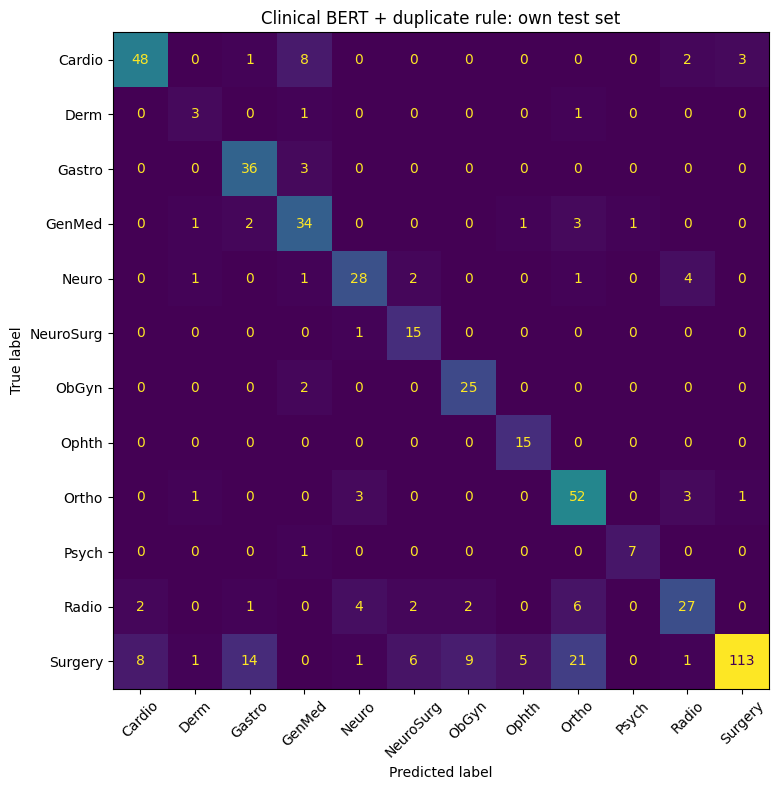

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

short = {"Cardiovascular-Pulmonary": "Cardio", "Dermatology": "Derm", "Gastroenterology": "Gastro",
         "General Medicine": "GenMed", "Neurology": "Neuro", "Neurosurgery": "NeuroSurg",
         "Obstetrics-Gynecology": "ObGyn", "Ophthalmology": "Ophth", "Orthopedic": "Ortho",
         "Psychiatry-Psychology": "Psych", "Radiology": "Radio", "Surgery": "Surgery"}
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(te["medical_specialty"], pred_rule, labels=LABELS,
    display_labels=[short[l] for l in LABELS], ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title("Clinical BERT + duplicate rule: own test set")
plt.tight_layout()
plt.savefig("figures/confusion_model3.png", dpi=200)   # for the paper
plt.savefig("figures/confusion_model3.pdf")            # vector version for LaTeX
plt.show()

### 8.6 Repeated runs with different seeds (lecture T4: run each model several times)
Every number above comes from **one** training run (seed 42). Fine-tuning depends on random choices (initial classification layer, batch order, dropout), so another seed gives a slightly different model. With only ~94 keywordless test notes, one note is about 1 point. So we train again with seeds 7 and 123 on the **same split** and report **mean ± standard deviation**. Only the seed changes; the data and settings stay identical.

As a bonus we also report the **ensemble**: average the three models' probabilities and pick the highest. Random quirks of each run partly cancel out.

Time: about 1–1.5 minutes per extra seed on an RTX 5080. The seed-42 run from section 7 is reused.

In [18]:
import torch.nn.functional as F

def layer_scores(name, y_true, y_pred):
    f1s = f1_score(y_true, y_pred, labels=LABELS, average=None, zero_division=0)
    return {f"{name} acc": accuracy_score(y_true, y_pred), f"{name} macro-F1": f1s.mean()}

runs, probs = [], []
for s in SEEDS:
    if s == SEED:
        sc = scores                                   # reuse the run from section 7
    else:
        print(f"--- training with seed {s}")
        m = train_model(tr, seed=s)
        sc = predict_scores(m, te)
        del m; torch.cuda.empty_cache() if device == "cuda" else None
    probs.append(F.softmax(torch.tensor(sc), dim=1).numpy())
    plain = np.array(LABELS)[sc.argmax(1)]
    dup = exclude_seen_labels(sc, te, tr)
    full = np.where(te_rule.notna(), te_rule, dup)
    y = te["medical_specialty"]
    runs.append({"seed": s, **layer_scores("BERT plain", y, plain), **layer_scores("+dup rule", y, dup),
                 **layer_scores("full system", y, full),
                 **layer_scores("no-keyword notes", y[no_kw], dup[no_kw])})

seed_table = pd.DataFrame(runs).set_index("seed")
summary = seed_table.agg(["mean", "std"])
display((pd.concat([seed_table, summary]) * 100).round(1))

# ensemble: average the probabilities of all seeds
ens = np.mean(probs, axis=0)
ens_dup = exclude_seen_labels(np.log(ens), te, tr)
ens_full = np.where(te_rule.notna(), te_rule, ens_dup)
print()
evaluate(f"ENSEMBLE of {len(SEEDS)} seeds, full system       ", te["medical_specialty"], ens_full)
evaluate(f"ENSEMBLE of {len(SEEDS)} seeds, notes without keywords", te["medical_specialty"][no_kw], ens_dup[no_kw])
(pd.concat([seed_table, summary]) * 100).round(2).to_csv("figures/model3_seeds.csv")

--- training with seed 7


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 35166.06it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISS

epoch 1/4  mean loss 2.248  (16s)
epoch 2/4  mean loss 1.307  (16s)
epoch 3/4  mean loss 0.889  (16s)
epoch 4/4  mean loss 0.736  (16s)
--- training with seed 123


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 26538.63it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISS

epoch 1/4  mean loss 2.269  (17s)
epoch 2/4  mean loss 1.388  (17s)
epoch 3/4  mean loss 0.936  (16s)
epoch 4/4  mean loss 0.796  (16s)


,BERT plain acc,BERT plain macro-F1,+dup rule acc,+dup rule macro-F1,full system acc,full system macro-F1,no-keyword notes acc,no-keyword notes macro-F1
42,54.9,58.1,75.5,74.6,95.1,92.7,72.3,62.2
7,55.2,59.0,76.8,77.1,96.4,94.6,79.8,66.7
123,55.6,58.3,77.2,76.7,95.7,93.5,75.5,63.8
mean,55.2,58.5,76.5,76.1,95.8,93.6,75.9,64.2
std,0.4,0.5,0.9,1.3,0.7,1.0,3.7,2.3



ENSEMBLE of 3 seeds, full system       : accuracy=0.959  macro-F1=0.944  worst-class F1=0.851 (General Medicine)
ENSEMBLE of 3 seeds, notes without keywords: accuracy=0.766  macro-F1=0.649  worst-class F1=0.000 (Dermatology)


## 9. Look at the mistakes
These are the errors of the **full system**, so mostly notes without keywords that BERT got wrong.

In [19]:
res = pd.DataFrame({"sample_name": te["sample_name"], "description": te["description"].str[:120],
                    "true": te["medical_specialty"], "predicted": pred_full,
                    "decided_by": np.where(no_kw, "BERT", "keyword rule")}, index=te.index)
mistakes = res[res.true != res.predicted]

all_labels = train[train.transcription.str.strip() != ""].groupby("transcription")["medical_specialty"].agg(set)
notes = te.loc[mistakes.index, "transcription"]
mistakes = mistakes.assign(other_valid_label=[p in all_labels.get(n, set()) for n, p in zip(notes, mistakes.predicted)])

print(f"{len(mistakes)} mistakes out of {len(res)}; "
      f"{mistakes.other_valid_label.sum()} of them predict a label the SAME note has elsewhere in the data")
mistakes[~mistakes.other_valid_label].head(10)     # genuine errors

26 mistakes out of 534; 2 of them predict a label the SAME note has elsewhere in the data


,sample_name,description,true,predicted,decided_by,other_valid_label
639,Gen Med Consult - 2,Initial clinic visit for foreign body in left...,General Medicine,Ophthalmology,BERT,False
688,Sleep Study Followup,Followup after a full-night sleep study perfo...,General Medicine,Psychiatry-Psychology,BERT,False
2418,"Heart Catheterization, Ventriculography, & Ang...","Left heart catheterization, coronary angiogra...",Surgery,Cardiovascular-Pulmonary,BERT,False
2086,,Tailor's bunionectomy with metatarsal osteotom...,Surgery,Orthopedic,BERT,False
768,Falls - Discharge Summary,Falls at home. Anxiety and depression. The ...,Neurology,General Medicine,BERT,False
189,Bronchiolitis - 2-month-old,2-month-old female - increased work of breathing.,Cardiovascular-Pulmonary,General Medicine,BERT,False
1125,Physical Exam and Pap -2,A white female who presents for complete phys...,Obstetrics-Gynecology,General Medicine,BERT,False
1,Difficulty Breathing - ER Visit,"The patient is 14 months old, comes in with a ...",Cardiovascular-Pulmonary,General Medicine,BERT,False
201,Pulmonary Consultation - 1,Obstructive sleep apnea syndrome. Loud snori...,Cardiovascular-Pulmonary,General Medicine,BERT,False
1025,Preeclampsia,"Preeclampsia, status post delivery with Cesare...",Obstetrics-Gynecology,General Medicine,BERT,False


## 10. Final model and `results.txt`
1. **Retrain from scratch on all 2,669 labelled notes** with the same settings (more data, so a slightly better model).
2. Read `test_no_labels.csv`. It has **no header row**, so we use `header=None` and name the columns ourselves.
3. Apply exactly the same steps: keep the raw keywords for the rule, drop the first keyword from BERT's text.
4. BERT + duplicate-note rule (against **all** the training data) for every note, then the keyword rule overrides wherever it applies.
5. Write one label per line, in the test file's order, with **Unix line endings** (`newline="\n"`). On Windows, Python would otherwise write `\r\n`, and a strict grader could read `Surgery\r` as a wrong label.

In [20]:
del model; torch.cuda.empty_cache() if device == "cuda" else None

final_model = train_model(train)

test = pd.read_csv("test_no_labels.csv", sep=";", header=None, dtype=str, keep_default_na=False,
                   names=["description", "sample_name", "transcription", "keywords"])
test["keywords_raw"] = test["keywords"]
test["keywords"] = test["keywords"].apply(drop_first_keyword)

test_scores = predict_scores(final_model, test)
bert_pred = exclude_seen_labels(test_scores, test, train)
test_rule = test["keywords_raw"].apply(keyword_specialty)
test_pred = np.where(test_rule.notna(), test_rule, bert_pred)
print(f"answered by keyword rule: {test_rule.notna().sum()} | by BERT: {test_rule.isna().sum()} "
      f"(of which seen in training -> duplicate rule applied: "
      f"{(test_rule.isna() & test['transcription'].isin(set(train['transcription'])) & (test['transcription'] != '')).sum()})")

with open("results.txt", "w", encoding="utf-8", newline="\n") as f:
    f.write("\n".join(test_pred) + "\n")
print(len(test), "test notes ->", len(test_pred), "predictions written to results.txt")
pd.Series(test_pred).value_counts()

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 47158.96it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISS

epoch 1/4  mean loss 2.174  (20s)
epoch 2/4  mean loss 1.121  (20s)
epoch 3/4  mean loss 0.791  (20s)
epoch 4/4  mean loss 0.666  (20s)
answered by keyword rule: 320 | by BERT: 78 (of which seen in training -> duplicate rule applied: 30)
398 test notes -> 398 predictions written to results.txt


Surgery                     148
Cardiovascular-Pulmonary     41
General Medicine             38
Radiology                    36
Orthopedic                   30
Gastroenterology             25
Neurology                    24
Obstetrics-Gynecology        18
Neurosurgery                 13
Psychiatry-Psychology        11
Ophthalmology                 9
Dermatology                   5
Name: count, dtype: int64

## Summary
| | |
|---|---|
| Model | Bio_ClinicalBERT fine-tuned (all layers) + linear classification head on [CLS] |
| Input | sample name [SEP] description [SEP] keywords (first removed) [SEP] transcription, max 512 tokens, no pre-processing |
| Training | 4 epochs, AdamW, lr 2e-5, warm-up 10% + linear decay, effective batch 16, weighted cross-entropy, bf16 |
| Inference | (1) keyword rule if the first keyword names a specialty; otherwise (2) BERT's highest score, (3) excluding labels the same note already has in the training data |
| Evaluation | same stratified 80/20 split as Model 1 (random_state = 42) |

**For the paper:** report the layer-by-layer table from 8.3 (plain → + duplicate rule → + keyword rule), BERT's score on notes without keywords (its real job), compare with Model 1 on the same split, and discuss the errors from section 9. State openly that layers 1 and 3 exploit how the corpus was built.